# ArthNex — S&P 500 Next-Session Forecasting

**Models:** Naive zero-return baseline, Linear Regression, LSTM  
**Ticker:** `^GSPC` (S&P 500 index)  
**Data start:** 2000-01-01  
**Target:** next-session close-to-close return  
**Input:** previous 60 trading sessions of raw OHLCV-style columns  
**Split:** chronological 80% train / 10% validation / 10% test

This notebook is a research pipeline, not a guarantee of profitable predictions. It uses no triple exponential smoothing and does not tune on the held-out test set. The final model and preprocessing artifacts are saved for a separate inference service.

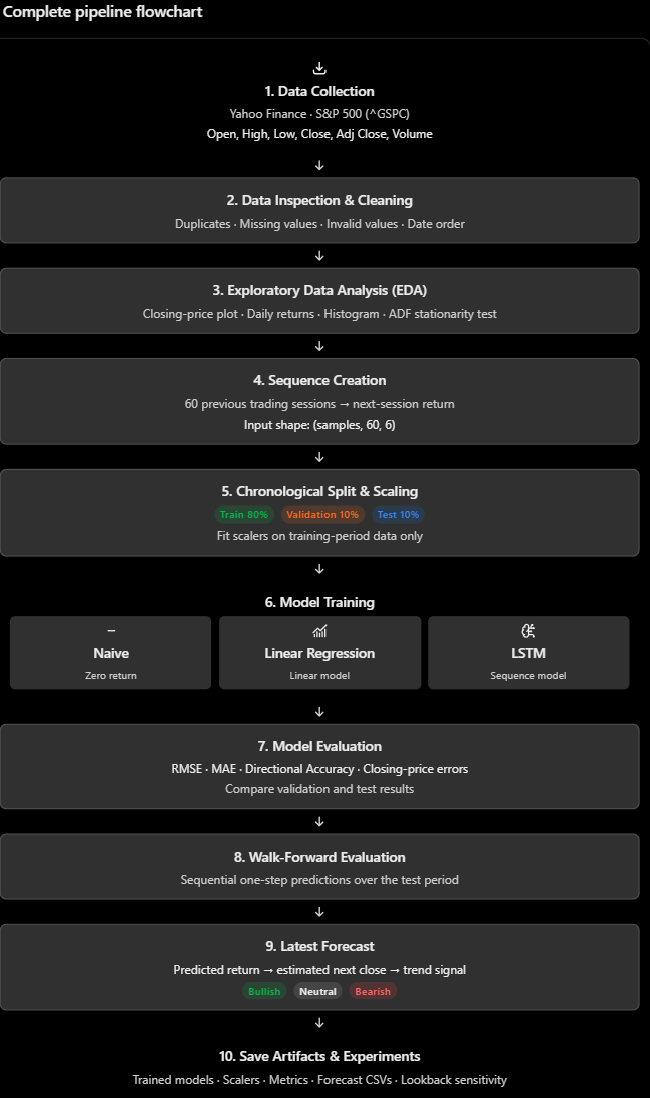

In [1]:
# Run once in Google Colab
!pip -q install yfinance pandas numpy matplotlib seaborn scikit-learn statsmodels joblib torch

In [2]:
import os, json, random, copy, warnings, platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import joblib
import sklearn
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

CFG = {
    "ticker": "^GSPC",
    "start": "2000-01-01",
    # Yahoo Finance treats end as exclusive. This includes data through 2026-10-15 if available.
    "end": "2026-10-16",
    "features": ["Open", "High", "Low", "Close", "Adj Close", "Volume"],
    "lookback": 60,
    "train_frac": 0.80,
    "val_frac": 0.10,
    "seed": 42,         # helps repeated experiments more consistent.
    "batch_size": 64,
    "max_epochs": 80,  # One complete pass through the training dataset.
    "patience": 10,    # Stops training if validation performance fails to improve for 10 consecutive epochs.
    "threshold": 0.005,  # ±0.5% rule for display labels only
    "model_version": "ArthNex-LSTM-returns-v3"
}

ART_DIR = "artifacts"
PLOT_DIR = os.path.join(ART_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def save_show(name):
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

set_seed(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| sklearn:", sklearn.__version__, "| torch:", torch.__version__)
print("Device:", DEVICE)

Python: 3.13.16
pandas: 2.2.3 | sklearn: 1.6.1 | torch: 2.11.0+cpu
Device: cpu


## 1. Download and inspect data

The notebook downloads the S&P 500 index from Yahoo Finance. A failed or empty download stops execution rather than silently producing a forecast from invalid data.

In [3]:
raw = yf.download(
    CFG["ticker"],
    start=CFG["start"],
    end=CFG["end"],
    auto_adjust=False,
    progress=False,
    actions=False
)

if raw is None or raw.empty:
    raise RuntimeError(
        "Yahoo Finance returned no data. Check internet access, ticker, and date range; "
        "do not publish a forecast when data retrieval fails."
    )

# yfinance can return MultiIndex columns depending on version/ticker.
if isinstance(raw.columns, pd.MultiIndex):
    # Select the first column level when the ticker is the second level.
    if CFG["ticker"] in raw.columns.get_level_values(-1):
        raw = raw.xs(CFG["ticker"], axis=1, level=-1)
    else:
        raw.columns = raw.columns.get_level_values(0)

missing_columns = [c for c in CFG["features"] if c not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns from Yahoo Finance: {missing_columns}")

raw = raw[CFG["features"]].copy()
raw.index = pd.to_datetime(raw.index)
if getattr(raw.index, "tz", None) is not None:
    raw.index = raw.index.tz_localize(None)
raw.index.name = "Date"
raw = raw.sort_index()

if raw.index.has_duplicates:
    print("Duplicate timestamps found; cleaning step will remove them.")

raw.to_csv("data/raw/gspc_download.csv")
print("Raw shape:", raw.shape)
print("Date range:", raw.index.min().date(), "to", raw.index.max().date())
display(raw.head())
display(raw.tail())
display(raw.isna().sum().rename("missing_count").to_frame())

Raw shape: (6737, 6)
Date range: 2000-01-03 to 2026-10-15


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2000-01-03,1469.250000,1478.000000,1438.359985,1455.219971,1455.219971,931800000
2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,1399.420044,1009000000
2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,1402.109985,1085500000
2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,1403.449951,1092300000
2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,1441.469971,1225200000


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2026-10-09,7786.359863,7820.569824,7779.339844,7811.540039,7811.540039,4782640000
2026-10-12,7813.040039,7821.669922,7796.939941,7807.240234,7807.240234,4148500000
2026-10-13,7795.270020,7814.149902,7786.109863,7805.450195,7805.450195,4869340000
2026-10-14,7774.180176,7789.149902,7693.310059,7718.939941,7718.939941,5955580000
2026-10-15,7687.310059,7754.149902,7669.660156,7744.060059,7744.060059,6055670000


,missing_count
Price,
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


## 2. Clean and validate data

Rows with missing or non-finite values, non-positive prices, negative volume, duplicate dates, or inconsistent OHLC values are removed. We also fail if too little usable data remains.

In [4]:
df = raw.copy()
clean_report = {"rows_downloaded": int(len(df))}

df = df[~df.index.duplicated(keep="last")].sort_index()
clean_report["duplicate_dates_removed"] = clean_report["rows_downloaded"] - int(len(df))

numeric = df[CFG["features"]].apply(pd.to_numeric, errors="coerce")     # Handle missing and invalid numbers
finite_mask = np.isfinite(numeric.to_numpy(dtype=float)).all(axis=1)
missing_mask = numeric.isna().any(axis=1).to_numpy()
valid_numeric_mask = finite_mask & ~missing_mask
clean_report["rows_with_missing_or_nonfinite_removed"] = int((~valid_numeric_mask).sum())
df = numeric.loc[valid_numeric_mask].copy()

price_cols = ["Open", "High", "Low", "Close", "Adj Close"]
bad_price = (df[price_cols] <= 0).any(axis=1)
bad_volume = df["Volume"] < 0
clean_report["nonpositive_price_or_negative_volume_removed"] = int((bad_price | bad_volume).sum())
df = df.loc[~(bad_price | bad_volume)].copy()

bad_ohlc = (
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1)) |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
)
clean_report["inconsistent_ohlc_removed"] = int(bad_ohlc.sum())
df = df.loc[~bad_ohlc].copy()

if len(df) <= CFG["lookback"] + 100:
    raise ValueError(f"Not enough cleaned rows for sequence modelling: {len(df)}")
if not df.index.is_monotonic_increasing or df.index.has_duplicates:
    raise AssertionError("Cleaned dates must be unique and strictly chronological.")
if not np.isfinite(df.to_numpy(dtype=float)).all():
    raise AssertionError("Cleaned dataset still contains non-finite values.")

clean_report["rows_after_cleaning"] = int(len(df))
clean_report["first_date"] = str(df.index.min().date())
clean_report["last_date"] = str(df.index.max().date())
print(json.dumps(clean_report, indent=2))
df.to_csv("data/processed/gspc_clean.csv")
display(df.describe().T)

{
  "rows_downloaded": 6737,
  "duplicate_dates_removed": 0,
  "rows_with_missing_or_nonfinite_removed": 0,
  "nonpositive_price_or_negative_volume_removed": 0,
  "inconsistent_ohlc_removed": 0,
  "rows_after_cleaning": 6737,
  "first_date": "2000-01-03",
  "last_date": "2026-10-15"
}


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,6737.0,2.415599e+03,1.664218e+03,679.280029,1.216960e+03,1.624620e+03,3.045750e+03,7.813040e+03
High,6737.0,2.429145e+03,1.671639e+03,695.270020,1.224700e+03,1.632070e+03,3.068670e+03,7.844520e+03
Low,6737.0,2.401055e+03,1.656354e+03,666.789978,1.210930e+03,1.614210e+03,3.012590e+03,7.805960e+03
Close,6737.0,2.415980e+03,1.664577e+03,676.530029,1.217280e+03,1.625960e+03,3.039420e+03,7.818930e+03
Adj Close,6737.0,2.415980e+03,1.664577e+03,676.530029,1.217280e+03,1.625960e+03,3.039420e+03,7.818930e+03
Volume,6737.0,3.477416e+09,1.535986e+09,0.000000,2.386210e+09,3.568340e+09,4.347500e+09,1.145623e+10


## 3. Exploratory data analysis and time-series diagnostics

The price level and return series have different statistical properties. ADF results are diagnostics, not proof that a series is always stationary or predictable.

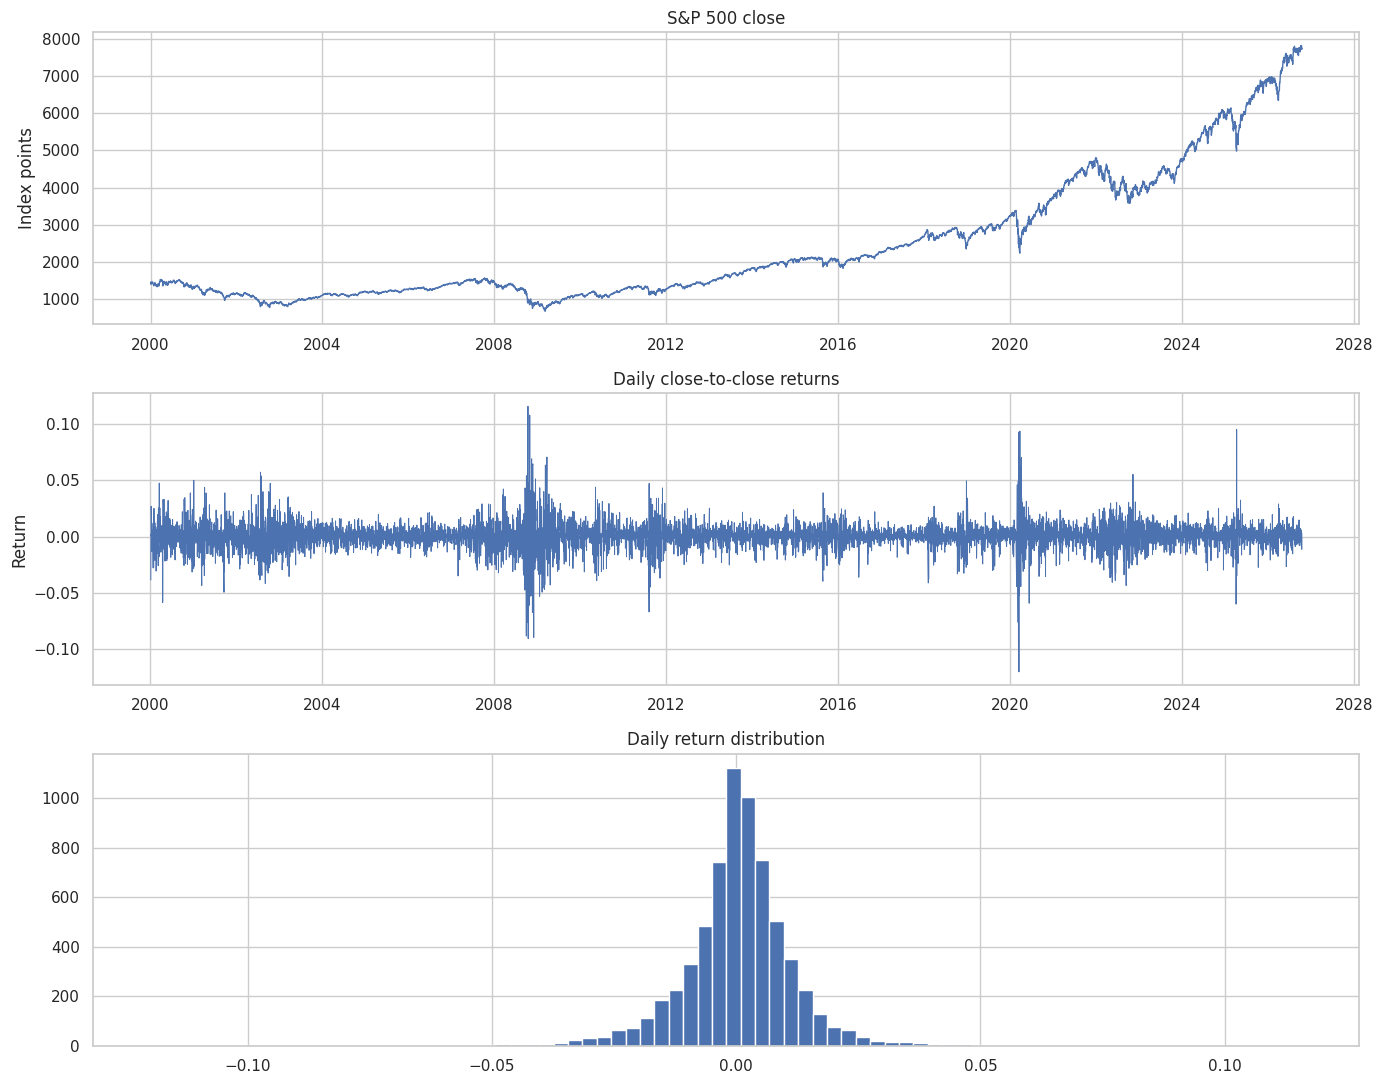

,series,adf_statistic,p_value,used_lags,observations,critical_1pct,critical_5pct,critical_10pct
0,Close level,3.456336,1.0,26,6710,-3.431325,-2.861971,-2.566999
1,Daily returns,-19.787468,0.0,18,6717,-3.431324,-2.861970,-2.566999


In [5]:
daily_returns = df["Close"].pct_change().dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 11))
axes[0].plot(df.index, df["Close"], linewidth=1)
axes[0].set_title("S&P 500 close")
axes[0].set_ylabel("Index points")
axes[1].plot(daily_returns.index, daily_returns, linewidth=0.7)
axes[1].set_title("Daily close-to-close returns")
axes[1].set_ylabel("Return")
axes[2].hist(daily_returns, bins=80)
axes[2].set_title("Daily return distribution")
save_show("eda_price_returns")

def adf_summary(series, name):
    result = adfuller(np.asarray(series.dropna(), dtype=float), autolag="AIC")
    return {
        "series": name,
        "adf_statistic": float(result[0]),
        "p_value": float(result[1]),
        "used_lags": int(result[2]),
        "observations": int(result[3]),
        "critical_1pct": float(result[4]["1%"]),
        "critical_5pct": float(result[4]["5%"]),
        "critical_10pct": float(result[4]["10%"])
    }

adf_df = pd.DataFrame([
    adf_summary(df["Close"], "Close level"),
    adf_summary(daily_returns, "Daily returns")
])
display(adf_df.round(6))


## 4. Create leakage-safe next-session sequences

For each target date *t*, the input is the previous 60 sessions (ending at *t-1*). The target is the return from the previous close to the target session's close. Inputs contain only information available before the target session.

In [6]:
FEATURES = CFG["features"]
L = int(CFG["lookback"])
values = df[FEATURES].to_numpy(dtype=np.float64)
closes = df["Close"].to_numpy(dtype=np.float64)
dates = pd.DatetimeIndex(df.index)

X_list, y_list, prev_list, target_dates = [], [], [], []
for target_pos in range(L, len(df)):
    X_list.append(values[target_pos-L:target_pos])
    y_list.append(closes[target_pos] / closes[target_pos-1] - 1.0)
    prev_list.append(closes[target_pos-1])
    target_dates.append(dates[target_pos])

X_all = np.stack(X_list).astype(np.float64)
y_all = np.asarray(y_list, dtype=np.float64)
prev_all = np.asarray(prev_list, dtype=np.float64)
target_dates = pd.DatetimeIndex(target_dates)

assert X_all.shape == (len(y_all), L, len(FEATURES))
assert len(prev_all) == len(y_all) == len(target_dates)
assert np.isfinite(X_all).all() and np.isfinite(y_all).all()
print("X shape:", X_all.shape, "| y shape:", y_all.shape)

X shape: (6677, 60, 6) | y shape: (6677,)


## 5. Chronological 80/10/10 split and train-only scaling

The test set remains held out for final reporting. Scalers are fit only using observations and target returns available in the training period. Later periods are transformed with those frozen scalers.

In [7]:
# prevent data leakage first split then train and test and then standardize
n = len(y_all)
i_train = int(n * CFG["train_frac"])
i_val = int(n * (CFG["train_frac"] + CFG["val_frac"]))
if not (0 < i_train < i_val < n):
    raise ValueError("Invalid train/validation/test split sizes.")

slices = {
    "train": slice(0, i_train),
    "val": slice(i_train, i_val),
    "test": slice(i_val, n)
}
split = {
    name: {
        "X": X_all[s],
        "y": y_all[s],
        "prev": prev_all[s],
        "dates": target_dates[s]
    }
    for name, s in slices.items()
}

for name, part in split.items():
    print(f"{name:>5}: n={len(part['y']):5d}, {part['dates'][0].date()} -> {part['dates'][-1].date()}")

assert split["train"]["dates"].max() < split["val"]["dates"].min()
assert split["val"]["dates"].max() < split["test"]["dates"].min()

# Last training target has its input window ending immediately before its target date.
train_input_end_exclusive = L + i_train - 1
x_scaler = StandardScaler().fit(values[:train_input_end_exclusive])
y_scaler = StandardScaler().fit(split["train"]["y"].reshape(-1, 1))

def scale_X(X):
    n_samples, steps, n_features = X.shape
    transformed = x_scaler.transform(X.reshape(-1, n_features))
    return transformed.reshape(n_samples, steps, n_features).astype(np.float32)

def scale_y(y):
    return y_scaler.transform(np.asarray(y).reshape(-1, 1)).ravel().astype(np.float32)

def inverse_y(y_scaled):
    return y_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()

for name in split:
    split[name]["Xs"] = scale_X(split[name]["X"])
    split[name]["ys"] = scale_y(split[name]["y"])

print("Scaler fitted using training-period data only.")

train: n= 5341, 2000-03-29 -> 2021-06-21
  val: n=  668, 2021-06-22 -> 2024-02-15
 test: n=  668, 2024-02-16 -> 2026-10-15
Scaler fitted using training-period data only.


## 6. Metrics and Naive / Linear Regression baselines

The naive baseline predicts a zero return (next close equals the previous close).

Linear Regression: Learns from historical data to predict tomorrow's return.

MAE (Mean Absolute Error) - Measures the average absolute difference between actual and predicted values.

RMSE (Root Mean Squared Error) - Measures prediction errors and penalizes large errors more heavily than MAE.

Directional Accuracy: How often do we correctly predict the market's direction?

In [8]:
def close_from_return(previous_close, returns):
    return np.asarray(previous_close, dtype=float) * (1.0 + np.asarray(returns, dtype=float))

def directional_accuracy(actual_return, predicted_return):
    actual_return = np.asarray(actual_return, dtype=float)
    predicted_return = np.asarray(predicted_return, dtype=float)
    mask = np.isfinite(actual_return) & np.isfinite(predicted_return) & (actual_return != 0)
    if not mask.any():
        return float("nan")
    return float((np.sign(actual_return[mask]) == np.sign(predicted_return[mask])).mean() * 100.0)

def calculate_metrics(actual_return, predicted_return, previous_close):
    actual_return = np.asarray(actual_return, dtype=float)
    predicted_return = np.asarray(predicted_return, dtype=float)
    previous_close = np.asarray(previous_close, dtype=float)
    valid = np.isfinite(actual_return) & np.isfinite(predicted_return) & np.isfinite(previous_close)
    actual_return, predicted_return, previous_close = (
        actual_return[valid], predicted_return[valid], previous_close[valid]
    )
    if len(actual_return) == 0:
        raise ValueError("No finite observations available for metrics.")
    actual_close = close_from_return(previous_close, actual_return)
    predicted_close = close_from_return(previous_close, predicted_return)
    return {
        "n": int(len(actual_return)),
        "Return_RMSE": float(np.sqrt(mean_squared_error(actual_return, predicted_return))),
        "Return_MAE": float(mean_absolute_error(actual_return, predicted_return)),
        "Close_RMSE_points": float(np.sqrt(mean_squared_error(actual_close, predicted_close))),
        "Close_MAE_points": float(mean_absolute_error(actual_close, predicted_close)),
        "Directional_Accuracy_pct": directional_accuracy(actual_return, predicted_return)
    }

def flatten_sequences(X):
    return X.reshape(len(X), -1)

predictions = {"Naive": {}, "LinearRegression": {}, "LSTM": {}}
for name, part in split.items():
    predictions["Naive"][name] = np.zeros(len(part["y"]), dtype=np.float64)

linear_model = LinearRegression()
linear_model.fit(flatten_sequences(split["train"]["Xs"]), split["train"]["ys"])

for name, part in split.items():
    linear_scaled_pred = linear_model.predict(flatten_sequences(part["Xs"]))
    predictions["LinearRegression"][name] = inverse_y(linear_scaled_pred)

baseline_rows = []
for model_name in ["Naive", "LinearRegression"]:
    for split_name in ["val", "test"]:
        part = split[split_name]
        baseline_rows.append({
            "Model": model_name,
            "Split": split_name,
            **calculate_metrics(part["y"], predictions[model_name][split_name], part["prev"])
        })
display(pd.DataFrame(baseline_rows).round(6))

,Model,Split,n,Return_RMSE,Return_MAE,Close_RMSE_points,Close_MAE_points,Directional_Accuracy_pct
0,Naive,val,668,0.011289,0.008399,46.848016,35.331291,0.000000
1,Naive,test,668,0.009672,0.006564,57.690739,40.601679,0.000000
2,LinearRegression,val,668,0.012993,0.009773,54.024778,41.096909,50.449102
3,LinearRegression,test,668,0.012273,0.008870,74.876830,55.341344,51.946108


## 7. Train and select the LSTM using validation only
My LSTM architecture takes the previous 60 trading days with 9 features per day as input. The LSTM layer learns patterns using three gates: forget, input, and output. I take the last time-step output and pass it through linear layers with ReLU and dropout. Finally, the model predicts the next trading day's return. I use Adam optimizer, MSE loss, and early stopping during training
Adam Optimizer - Updates weights to reduce errors

Linearity -	Straight-line relationship

Non-linearity =	relationship between input and output is not a straight line.[Learns complex relationships]

ReLU - Negative values become zero and keeps positive values unchanged.

Dropout - temporarily switches off some neurons during training so the model does not depend too much on particular neurons.Reduces overfitting

The sequence is:
1. Make predictions.
2. Calculate MSE loss.
3. Backpropagate the loss to calculate gradients.
4. Update model weights using the Adam optimizer.

Candidate 1: {'hidden': 32, 'layers': 1, 'dropout': 0.0, 'lr': 0.001} | validation return RMSE=0.01128199
Candidate 2: {'hidden': 64, 'layers': 1, 'dropout': 0.0, 'lr': 0.001} | validation return RMSE=0.01127787
Candidate 3: {'hidden': 64, 'layers': 1, 'dropout': 0.1, 'lr': 0.0005} | validation return RMSE=0.01128006


,hidden,layers,dropout,lr,epochs_run,validation_return_RMSE
1,64,1,0.0,0.0010,13,0.011278
2,64,1,0.1,0.0005,21,0.011280
0,32,1,0.0,0.0010,20,0.011282


Selected using validation RMSE only: {'hidden': 64, 'layers': 1, 'dropout': 0.0, 'lr': 0.001}


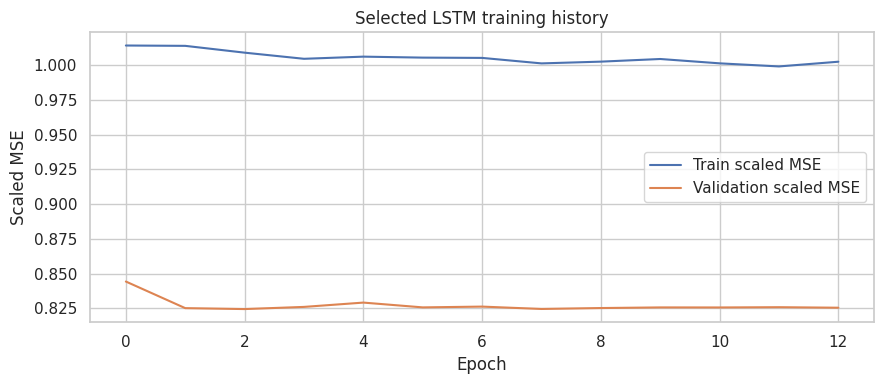

In [9]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=64, layers=1, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden,
            num_layers=layers,
            batch_first=True,
            dropout=dropout if layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(output[:, -1, :]).squeeze(-1)

def make_loader(X, y, shuffle):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )
    generator = torch.Generator()
    generator.manual_seed(CFG["seed"])
    return DataLoader(
        dataset,
        batch_size=CFG["batch_size"],
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=0
    )

train_loader = make_loader(split["train"]["Xs"], split["train"]["ys"], True)
val_loader = make_loader(split["val"]["Xs"], split["val"]["ys"], False)

@torch.no_grad()
def predict_scaled_model(model, X, batch_size=512):
    model.eval()
    outputs = []
    for start in range(0, len(X), batch_size):
        batch = torch.tensor(X[start:start+batch_size], dtype=torch.float32, device=DEVICE)
        outputs.append(model(batch).detach().cpu().numpy())
    return np.concatenate(outputs) if outputs else np.array([], dtype=float)

def fit_candidate(config, seed):
    set_seed(seed)
    model = LSTMRegressor(
        n_features=len(FEATURES),
        hidden=config["hidden"],
        layers=config["layers"],
        dropout=config["dropout"]
    ).to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=1e-5
    )
    best_val_loss = float("inf")
    best_state = None
    wait = 0
    history = {"train_loss": [], "val_loss": []}
    epochs_run = 0

    for epoch in range(CFG["max_epochs"]):
        model.train()
        train_sum, train_count = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(xb), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss; aborting candidate.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_sum += float(loss.item()) * len(xb)
            train_count += len(xb)

        model.eval()
        val_sum, val_count = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                loss_sum = nn.functional.mse_loss(model(xb), yb, reduction="sum")
                val_sum += float(loss_sum.item())
                val_count += len(xb)

        train_loss = train_sum / max(train_count, 1)
        val_loss = val_sum / max(val_count, 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        epochs_run = epoch + 1

        if val_loss < best_val_loss - 1e-8:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= CFG["patience"]:
                break

    if best_state is None:
        raise RuntimeError("No valid LSTM checkpoint was created.")
    model.load_state_dict(best_state)
    val_prediction = inverse_y(predict_scaled_model(model, split["val"]["Xs"]))
    val_rmse = float(np.sqrt(mean_squared_error(split["val"]["y"], val_prediction)))
    return model, val_rmse, history, epochs_run

CANDIDATES = [
    {"hidden": 32, "layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"hidden": 64, "layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"hidden": 64, "layers": 1, "dropout": 0.1, "lr": 5e-4}
]

candidate_rows = []
best_model, best_config, best_history, best_val_rmse = None, None, None, float("inf")
for idx, config in enumerate(CANDIDATES):
    model_i, val_rmse, history_i, epochs_run = fit_candidate(config, CFG["seed"] + idx)
    candidate_rows.append({
        **config,
        "epochs_run": epochs_run,
        "validation_return_RMSE": val_rmse
    })
    print(f"Candidate {idx+1}: {config} | validation return RMSE={val_rmse:.8f}")
    if val_rmse < best_val_rmse:
        best_model = copy.deepcopy(model_i)
        best_config = config.copy()
        best_history = history_i
        best_val_rmse = val_rmse

candidate_df = pd.DataFrame(candidate_rows).sort_values("validation_return_RMSE")
display(candidate_df)
print("Selected using validation RMSE only:", best_config)

plt.figure(figsize=(9, 4))
plt.plot(best_history["train_loss"], label="Train scaled MSE")
plt.plot(best_history["val_loss"], label="Validation scaled MSE")
plt.xlabel("Epoch")
plt.ylabel("Scaled MSE")
plt.title("Selected LSTM training history")
plt.legend()
save_show("lstm_training_history")

## 8. Evaluate the three models

Validation metrics can inform model selection. The test metrics are final held-out results and should not be used to tune the model after inspecting them.

,Model,Split,n,Return_RMSE,Return_MAE,Close_RMSE_points,Close_MAE_points,Directional_Accuracy_pct
0,Naive,val,668,0.011289,0.008399,46.848016,35.331291,0.000000
1,Naive,test,668,0.009672,0.006564,57.690739,40.601679,0.000000
2,LinearRegression,val,668,0.012993,0.009773,54.024778,41.096909,50.449102
3,LinearRegression,test,668,0.012273,0.008870,74.876830,55.341344,51.946108
4,LSTM,val,668,0.011278,0.008395,46.816233,35.310584,51.497006
5,LSTM,test,668,0.009651,0.006538,57.566741,40.447418,55.389222


Best model by validation return RMSE: LSTM
Held-out test ranking (report as-is; do not tune on it):


,Model,Split,n,Return_RMSE,Return_MAE,Close_RMSE_points,Close_MAE_points,Directional_Accuracy_pct
0,LSTM,test,668,0.009651,0.006538,57.566741,40.447418,55.389222
1,Naive,test,668,0.009672,0.006564,57.690739,40.601679,0.000000
2,LinearRegression,test,668,0.012273,0.008870,74.876830,55.341344,51.946108


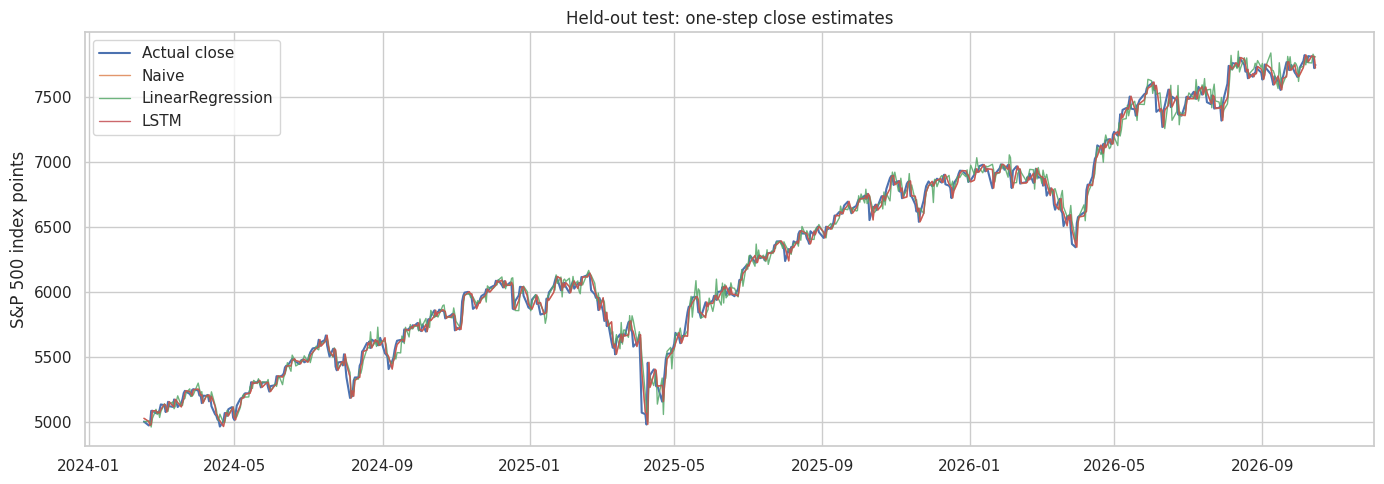

On this held-out period, LSTM has lower return RMSE than both baselines.


In [10]:
for split_name, part in split.items():
    predictions["LSTM"][split_name] = inverse_y(
        predict_scaled_model(best_model, part["Xs"])
    )

metric_rows = []
for model_name in predictions:
    for split_name in ["val", "test"]:
        part = split[split_name]
        metric_rows.append({
            "Model": model_name,
            "Split": split_name,
            **calculate_metrics(part["y"], predictions[model_name][split_name], part["prev"])
        })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(6))

validation_ranking = (
    metrics_df[metrics_df["Split"] == "val"]
    .sort_values("Return_RMSE")
    .reset_index(drop=True)
)
selected_by_validation = str(validation_ranking.loc[0, "Model"])
print("Best model by validation return RMSE:", selected_by_validation)

test_ranking = (
    metrics_df[metrics_df["Split"] == "test"]
    .sort_values("Return_RMSE")
    .reset_index(drop=True)
)
print("Held-out test ranking (report as-is; do not tune on it):")
display(test_ranking)

plt.figure(figsize=(14, 5))
test_part = split["test"]
actual_close = close_from_return(test_part["prev"], test_part["y"])
plt.plot(test_part["dates"], actual_close, label="Actual close", linewidth=1.5)
for model_name in predictions:
    pred_close = close_from_return(test_part["prev"], predictions[model_name]["test"])
    plt.plot(test_part["dates"], pred_close, label=model_name, alpha=0.85, linewidth=1)
plt.title("Held-out test: one-step close estimates")
plt.ylabel("S&P 500 index points")
plt.legend()
save_show("test_close_predictions")

# Clearly state whether the LSTM beats the best simple baseline on this test period.
test_rmse = test_ranking.set_index("Model")["Return_RMSE"]
best_baseline_rmse = min(test_rmse["Naive"], test_rmse["LinearRegression"])
if test_rmse["LSTM"] < best_baseline_rmse:
    print("On this held-out period, LSTM has lower return RMSE than both baselines.")
else:
    print("On this held-out period, LSTM does NOT beat both baselines on return RMSE.")

## 9. Walk-forward test evaluation

It tests how well the models predict the next trading day's return across the test period, using historical data available before each prediction.

Formula = Current day closing value - Previous day closing value / previous day closing value

,Model,n,Return_RMSE,Return_MAE,Close_RMSE_points,Close_MAE_points,Directional_Accuracy_pct
2,LSTM,668,0.009651,0.006538,57.566741,40.447418,55.389222
0,Naive,668,0.009672,0.006564,57.690739,40.601679,0.000000
1,LinearRegression,668,0.012273,0.008870,74.876832,55.341344,51.946108


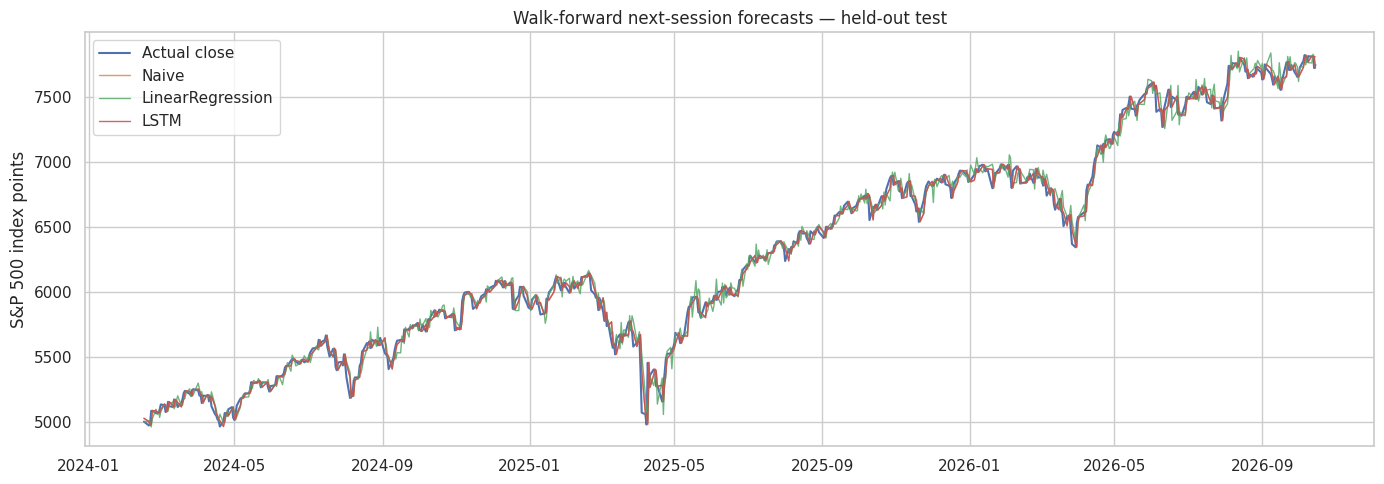

In [11]:
wf_rows = []
for target_pos in range(i_val, len(y_all)):
    target_row = target_pos + L
    input_window = df[FEATURES].iloc[target_row-L:target_row].to_numpy(dtype=np.float64)
    if input_window.shape != (L, len(FEATURES)):
        raise AssertionError(f"Unexpected walk-forward window shape: {input_window.shape}")
    if not np.isfinite(input_window).all():
        raise ValueError(f"Non-finite input in walk-forward window for {df.index[target_row].date()}")

    prev_close = float(df["Close"].iloc[target_row-1])
    actual_close_value = float(df["Close"].iloc[target_row])
    actual_return_value = actual_close_value / prev_close - 1.0
    scaled_window = x_scaler.transform(input_window).astype(np.float32)[None, :, :]

    lr_return = float(inverse_y(linear_model.predict(scaled_window.reshape(1, -1)))[0])
    lstm_return = float(inverse_y(predict_scaled_model(best_model, scaled_window))[0])
    naive_return = 0.0

    wf_rows.append({
        "Date": df.index[target_row],
        "PreviousClose": prev_close,
        "ActualClose": actual_close_value,
        "ActualReturn": actual_return_value,
        "NaiveReturn": naive_return,
        "LinearRegressionReturn": lr_return,
        "LSTMReturn": lstm_return,
        "NaiveClose": float(close_from_return(prev_close, naive_return)),
        "LinearRegressionClose": float(close_from_return(prev_close, lr_return)),
        "LSTMClose": float(close_from_return(prev_close, lstm_return))
    })

wf = pd.DataFrame(wf_rows).set_index("Date")
if wf.empty:
    raise RuntimeError("Walk-forward test produced no predictions.")

wf_metric_rows = []
for model_name, return_column in [
    ("Naive", "NaiveReturn"),
    ("LinearRegression", "LinearRegressionReturn"),
    ("LSTM", "LSTMReturn")
]:
    wf_metric_rows.append({
        "Model": model_name,
        **calculate_metrics(wf["ActualReturn"], wf[return_column], wf["PreviousClose"])
    })
wf_metrics = pd.DataFrame(wf_metric_rows).sort_values("Return_RMSE")
display(wf_metrics.round(6))

plt.figure(figsize=(14, 5))
plt.plot(wf.index, wf["ActualClose"], label="Actual close", linewidth=1.5)
for model_name in ["Naive", "LinearRegression", "LSTM"]:
    plt.plot(wf.index, wf[f"{model_name}Close"], label=model_name, linewidth=1, alpha=0.85)
plt.title("Walk-forward next-session forecasts — held-out test")
plt.ylabel("S&P 500 index points")
plt.legend()
save_show("walk_forward_test")

## 10. Generate the latest next-session forecast

The forecast uses the last 60 observed rows. The trend label is a threshold-based display convention, not a probability or a guarantee. The latest data date is checked against the configured end date; if data is stale, treat the result as stale and do not publish it as today's forecast.

Threshold = PPrevious Close - Previous Close  / Predicted Close​×100


Threshold greater than 0.5 = bullish
          lesser than 0.5 = Bearish
          Btw -0.5 to 0.5 = Neutral

In [12]:
def return_to_signal(return_value, threshold=CFG["threshold"]):
    if not np.isfinite(return_value):
        return "UNAVAILABLE"
    if return_value > threshold:
        return "BULLISH"
    if return_value < -threshold:
        return "BEARISH"
    return "NEUTRAL"

if len(df) < L:
    raise ValueError(f"Need at least {L} rows for latest forecast.")
last_window = df[FEATURES].iloc[-L:].to_numpy(dtype=np.float64)
last_close = float(df["Close"].iloc[-1])
last_date = pd.Timestamp(df.index[-1])

if not np.isfinite(last_window).all() or not np.isfinite(last_close) or last_close <= 0:
    raise ValueError("Latest input window or close is invalid; refusing to forecast.")

last_scaled = x_scaler.transform(last_window).astype(np.float32)[None, :, :]
latest_returns = {
    "Naive": 0.0,
    "LinearRegression": float(inverse_y(linear_model.predict(last_scaled.reshape(1, -1)))[0]),
    "LSTM": float(inverse_y(predict_scaled_model(best_model, last_scaled))[0])
}

generated_at = datetime.now(timezone.utc).isoformat()
forecast_rows = []
for model_name, predicted_return in latest_returns.items():
    if not np.isfinite(predicted_return):
        raise FloatingPointError(f"{model_name} produced a non-finite forecast.")
    forecast_rows.append({
        "ticker": CFG["ticker"],
        "model": model_name,
        "as_of_date": str(last_date.date()),
        "current_close": last_close,
        "predicted_next_close": float(close_from_return(last_close, predicted_return)),
        "predicted_return_decimal": predicted_return,
        "predicted_return_pct": predicted_return * 100.0,
        "trend_threshold_pct": CFG["threshold"] * 100.0,
        "trend": return_to_signal(predicted_return),
        "model_version": CFG["model_version"] if model_name == "LSTM" else model_name,
        "generated_at_utc": generated_at
    })

forecast_df = pd.DataFrame(forecast_rows)
display(forecast_df.round(5))
print("Latest available data date:", last_date.date())
print("Validation-selected model:", selected_by_validation)
print("Forecasts are uncertain and are not investment advice.")

,ticker,model,as_of_date,current_close,predicted_next_close,predicted_return_decimal,predicted_return_pct,trend_threshold_pct,trend,model_version,generated_at_utc
0,^GSPC,Naive,2026-10-15,7744.06006,7744.06006,0.00000,0.00000,0.5,NEUTRAL,Naive,2026-10-16T17:15:11.460199+00:00
1,^GSPC,LinearRegression,2026-10-15,7744.06006,7736.28681,-0.00100,-0.10038,0.5,NEUTRAL,LinearRegression,2026-10-16T17:15:11.460199+00:00
2,^GSPC,LSTM,2026-10-15,7744.06006,7747.20178,0.00041,0.04057,0.5,NEUTRAL,ArthNex-LSTM-returns-v3,2026-10-16T17:15:11.460199+00:00


Latest available data date: 2026-10-15
Validation-selected model: LSTM
Forecasts are uncertain and are not investment advice.


## 11. Save model artifacts, metrics, and metadata

The LSTM architecture is described in `config.json`, and its state dictionary is saved separately. A production inference service must recreate the same architecture and load the matching scaler/model versions. The artifacts are not a complete deployed service by themselves.

In [13]:
# Final integrity checks before writing artifacts.
required_forecast_columns = {
    "ticker", "model", "as_of_date", "current_close",
    "predicted_next_close", "predicted_return_pct", "trend"
}
if not required_forecast_columns.issubset(forecast_df.columns):
    raise AssertionError("Forecast output schema is incomplete.")
if forecast_df[list(required_forecast_columns - {"ticker", "model", "as_of_date", "trend"})].isna().any().any():
    raise AssertionError("Forecast output contains missing numeric fields.")

metrics_df.to_csv(os.path.join(ART_DIR, "metrics_validation_test.csv"), index=False)
candidate_df.to_csv(os.path.join(ART_DIR, "lstm_candidate_results.csv"), index=False)
wf.to_csv(os.path.join(ART_DIR, "walk_forward_test_predictions.csv"))
wf_metrics.to_csv(os.path.join(ART_DIR, "walk_forward_metrics.csv"), index=False)
forecast_df.to_csv(os.path.join(ART_DIR, "latest_forecasts.csv"), index=False)
adf_df.to_csv(os.path.join(ART_DIR, "adf_diagnostics.csv"), index=False)

joblib.dump(x_scaler, os.path.join(ART_DIR, "feature_scaler.pkl"))
joblib.dump(y_scaler, os.path.join(ART_DIR, "return_scaler.pkl"))
joblib.dump(linear_model, os.path.join(ART_DIR, "linear_regression.joblib"))
torch.save(best_model.cpu().state_dict(), os.path.join(ART_DIR, "lstm_best.pt"))
best_model.to(DEVICE)

metadata = {
    **CFG,
    "selected_lstm": best_config,
    "selected_by_validation": selected_by_validation,
    "feature_count": len(FEATURES),
    "lookback": L,
    "input_shape_per_sample": [L, len(FEATURES)],
    "target": "next_session_close_to_close_return",
    "train_date_start": str(split["train"]["dates"][0].date()),
    "train_date_end": str(split["train"]["dates"][-1].date()),
    "validation_date_start": str(split["val"]["dates"][0].date()),
    "validation_date_end": str(split["val"]["dates"][-1].date()),
    "test_date_start": str(split["test"]["dates"][0].date()),
    "test_date_end": str(split["test"]["dates"][-1].date()),
    "data_as_of": str(df.index[-1].date()),
    "generated_at_utc": generated_at,
    "device_used_for_training": str(DEVICE),
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "torch_version": torch.__version__,
    "notes": [
        "Test set must not be used for model selection.",
        "Threshold labels are heuristics, not calibrated probabilities.",
        "Run inference only after validating data freshness and schema.",
        "No model can guarantee accurate forecasts or positive investment returns."
    ]
}
with open(os.path.join(ART_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Artifacts saved under:", os.path.abspath(ART_DIR))
print("\nFiles:")
for root, _, filenames in os.walk(ART_DIR):
    for filename in sorted(filenames):
        print(" -", os.path.relpath(os.path.join(root, filename), ART_DIR))

Artifacts saved under: /content/artifacts

Files:
 - adf_diagnostics.csv
 - config.json
 - feature_scaler.pkl
 - latest_forecasts.csv
 - linear_regression.joblib
 - lstm_best.pt
 - lstm_candidate_results.csv
 - metrics_validation_test.csv
 - return_scaler.pkl
 - walk_forward_metrics.csv
 - walk_forward_test_predictions.csv
 - plots/eda_price_returns.png
 - plots/lstm_training_history.png
 - plots/test_close_predictions.png
 - plots/walk_forward_test.png


### Comprehensive Lookback Sensitivity Analysis (RMSE, MAE, & Directional Accuracy)

We will now run a detailed evaluation on the test split across lookbacks of 7, 30, 60, and 90 days, calculating:
- **Return RMSE**
- **Return MAE**
- **Directional Accuracy (%)**

Naive Model: Predicts a 0% return.

Linear Regression: Learns relationships between historical features and next-day returns.

LSTM: Learns sequential patterns using an LSTM layer with 64 hidden units, trained for 15 epochs.

30 days: Captures roughly 1.5 months of trading.

60 days: Balances historical information and model complexity.

90 days: Provides more history but may add unnecessary information.

In [21]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import torch
import torch.nn as nn

# Standardize access to features
clean_df = pd.read_csv("data/processed/gspc_clean.csv", index_col="Date", parse_dates=True)
features_list = CFG["features"]
lookbacks = [30, 60, 90]
expanded_results = []

for L in lookbacks:
    # 1. Create sequences with lookback L
    values_l = clean_df[features_list].to_numpy(dtype=np.float64)
    closes_l = clean_df["Close"].to_numpy(dtype=np.float64)

    X_list, y_list, prev_list = [], [], []
    for target_pos in range(L, len(clean_df)):
        X_list.append(values_l[target_pos-L:target_pos])
        y_list.append(closes_l[target_pos] / closes_l[target_pos-1] - 1.0)
        prev_list.append(closes_l[target_pos-1])

    X_arr = np.stack(X_list).astype(np.float32)
    y_arr = np.asarray(y_list, dtype=np.float32)
    prev_arr = np.asarray(prev_list, dtype=np.float32)

    # 2. Chronological Split (80/10/10)
    num_samples = len(y_arr)
    idx_train = int(num_samples * CFG["train_frac"])
    idx_val = int(num_samples * (CFG["train_frac"] + CFG["val_frac"]))

    train_X_raw = X_arr[:idx_train]
    train_y_raw = y_arr[:idx_train]
    test_X_raw = X_arr[idx_val:]
    test_y_raw = y_arr[idx_val:]

    # 3. Scale Features using Train Set only
    xs_scaler = StandardScaler().fit(values_l[:L + idx_train - 1])
    ys_scaler = StandardScaler().fit(train_y_raw.reshape(-1, 1))

    def transform_X(X):
        n_s, steps, n_f = X.shape
        return xs_scaler.transform(X.reshape(-1, n_f)).reshape(n_s, steps, n_f).astype(np.float32)

    train_Xs = transform_X(train_X_raw)
    test_Xs = transform_X(test_X_raw)
    train_ys = ys_scaler.transform(train_y_raw.reshape(-1, 1)).ravel()

    # Helper to calculate directional accuracy
    def get_dir_acc(actual, pred):
        actual = np.asarray(actual)
        pred = np.asarray(pred)
        mask = (actual != 0)
        if not mask.any():
            return 0.0
        return float((np.sign(actual[mask]) == np.sign(pred[mask])).mean() * 100.0)

    # --- Model Predictions ---
    # A. Naive baseline
    naive_pred = np.zeros_like(test_y_raw)

    # B. Linear Regression
    lr = LinearRegression()
    lr.fit(train_Xs.reshape(len(train_Xs), -1), train_ys)
    lr_pred_scaled = lr.predict(test_Xs.reshape(len(test_Xs), -1))
    lr_pred = ys_scaler.inverse_transform(lr_pred_scaled.reshape(-1, 1)).ravel()

    # C. LSTM (Minimal epochs for fair timing)
    class SimpleLSTM(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(len(features_list), 64, batch_first=True)
            self.head = nn.Sequential(
                nn.LayerNorm(64),
                nn.Linear(64, 1)
            )
        def forward(self, x):
            out, _ = self.lstm(x)
            return self.head(out[:, -1, :]).squeeze(-1)

    set_seed(CFG["seed"])
    lstm_model = SimpleLSTM().to(DEVICE)
    optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

    lstm_model.train()
    for epoch in range(15):
        optimizer.zero_grad()
        inputs = torch.tensor(train_Xs, dtype=torch.float32, device=DEVICE)
        targets = torch.tensor(train_ys, dtype=torch.float32, device=DEVICE)
        loss = nn.functional.mse_loss(lstm_model(inputs), targets)
        loss.backward()
        optimizer.step()

    lstm_model.eval()
    with torch.no_grad():
        test_inputs = torch.tensor(test_Xs, dtype=torch.float32, device=DEVICE)
        lstm_pred_scaled = lstm_model(test_inputs).cpu().numpy()
    lstm_pred = ys_scaler.inverse_transform(lstm_pred_scaled.reshape(-1, 1)).ravel()

    # Log Metrics
    for m_name, pred_val in [("Naive", naive_pred), ("LinearRegression", lr_pred), ("LSTM", lstm_pred)]:
        rmse = np.sqrt(mean_squared_error(test_y_raw, pred_val))
        mae = mean_absolute_error(test_y_raw, pred_val)
        dir_acc = get_dir_acc(test_y_raw, pred_val) if m_name != "Naive" else 0.0
        expanded_results.append({
            "Lookback": L,
            "Model": m_name,
            "RMSE": rmse,
            "MAE": mae,
            "Dir_Accuracy_Pct": dir_acc
        })

sens_df = pd.DataFrame(expanded_results)
display(sens_df.round(6))

,Lookback,Model,RMSE,MAE,Dir_Accuracy_Pct
0,30,Naive,0.009675,0.006578,0.000000
1,30,LinearRegression,0.011973,0.008600,49.776453
2,30,LSTM,0.009653,0.006534,55.588674
3,60,Naive,0.009672,0.006564,0.000000
4,60,LinearRegression,0.012275,0.008872,51.946108
5,60,LSTM,0.009650,0.006521,55.538922
6,90,Naive,0.009689,0.006576,0.000000
7,90,LinearRegression,0.012621,0.009220,49.624060
8,90,LSTM,0.009666,0.006531,55.639098


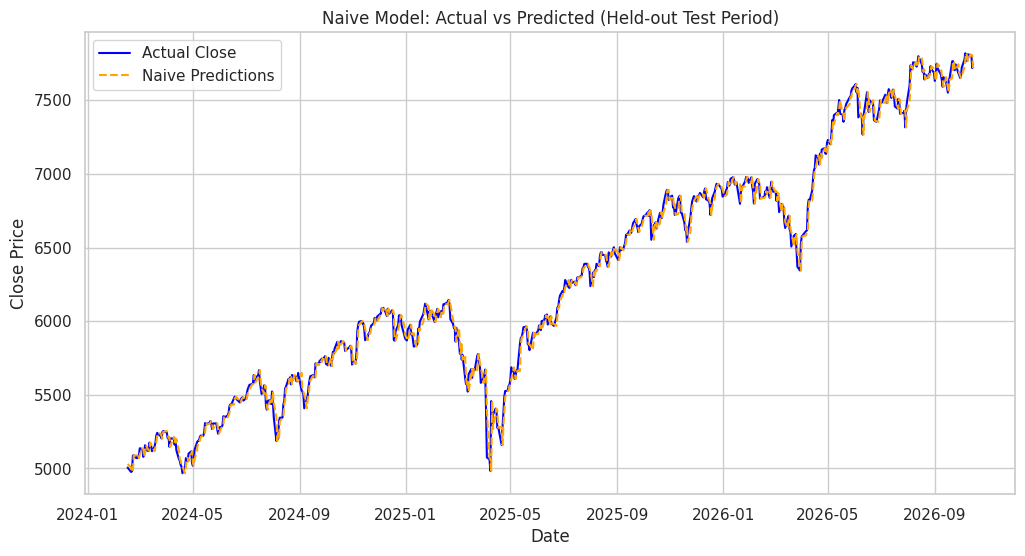

In [16]:
import matplotlib.pyplot as plt

# Retrieve test split from the defined 'split' variable
test_part = split["test"]

# Convert returns to close price series
actual_close = close_from_return(test_part["prev"], test_part["y"])
naive_predicted_close = close_from_return(test_part["prev"], predictions["Naive"]["test"])

plt.figure(figsize=(12, 6))
plt.plot(test_part["dates"], actual_close, label="Actual Close", color="blue")
plt.plot(test_part["dates"], naive_predicted_close, label="Naive Predictions", color="orange", linestyle="--")

plt.title("Naive Model: Actual vs Predicted (Held-out Test Period)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

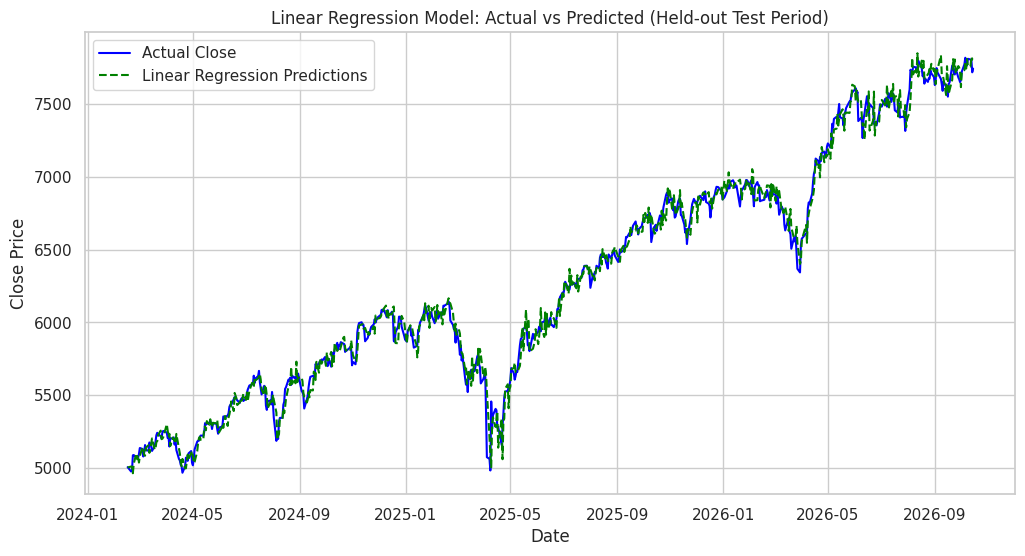

In [18]:
import matplotlib.pyplot as plt

# Retrieve test split from the defined 'split' variable
test_part = split["test"]

# Convert returns to close price series
actual_close = close_from_return(test_part["prev"], test_part["y"])
linear_predicted_close = close_from_return(test_part["prev"], predictions["LinearRegression"]["test"])

plt.figure(figsize=(12, 6))
plt.plot(test_part["dates"], actual_close, label="Actual Close", color="blue")
plt.plot(test_part["dates"], linear_predicted_close, label="Linear Regression Predictions", color="green", linestyle="--")

plt.title("Linear Regression Model: Actual vs Predicted (Held-out Test Period)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

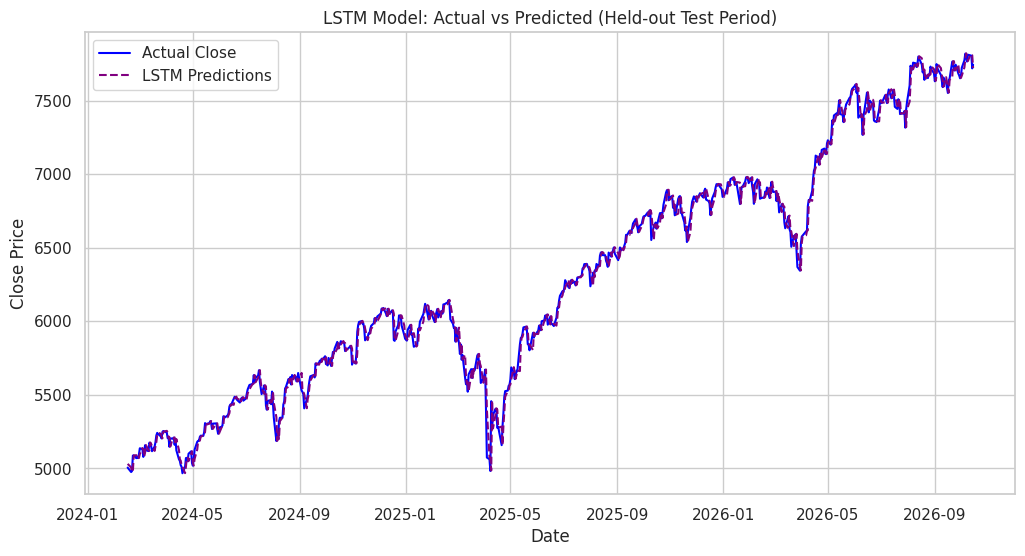

In [20]:
import matplotlib.pyplot as plt

# Retrieve test split from the defined 'split' variable
test_part = split["test"]

# Convert returns to close price series
actual_close = close_from_return(test_part["prev"], test_part["y"])
lstm_predicted_close = close_from_return(test_part["prev"], predictions["LSTM"]["test"])

plt.figure(figsize=(12, 6))
plt.plot(test_part["dates"], actual_close, label="Actual Close", color="blue")
plt.plot(test_part["dates"], lstm_predicted_close, label="LSTM Predictions", color="purple", linestyle="--")

plt.title("LSTM Model: Actual vs Predicted (Held-out Test Period)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()